# Практична робота №3
## TF-IDF зважені FastText-ембеддинги для класифікації текстів

Студент: Панчишин Володимир

**Мета:** Порівняти Mean Pooling і TF-IDF Weighted Mean для FastText та три класифікатори на даних, заданих методичкою.

Джерело завдання: https://github.com/olehsinkevych/machine-learning

**Відтворення:** середовище Python 3.12, залежності в requirements.txt; перед запуском усієї роботи завантажте дані командою `python download_data.py`. Усі результати нижче отримуються виконанням коду, а не копіюванням готових таблиць.

In [1]:
from pathlib import Path
import sys, os
for name in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:
    os.environ.setdefault(name, '2')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'project' / 'common.py').is_file())
sys.path.insert(0, str(ROOT / 'project'))
import common
from IPython.display import display, Image
import pandas as pd
import json

## 1. Теоретичні пояснення та відповіді на питання

### FastText
Слово представляється через символьні n-грами, тому вектор можна одержати й для слова поза навчальним словником. Використовую 100-вимірні вектори skip-gram, вікно 5, min_count=2, 20 епох і один worker для відтворюваності.

### Правильне TF-IDF зважування
Mean Pooling враховує частоту появи слів. Для зваженого варіанта кожний унікальний термін додається один раз із вагою count(t,d)·idf(t). Якщо повторно пройти по всіх входженнях і помножити на TF, частота помилково врахується двічі. IDF і FastText навчаються тільки на Train. Для слів без відомої IDF вагу встановлено 0; якщо вся сума ваг нульова, використовується звичайне усереднення.

### Класифікатори і геометрія
LogReg задає лінійну межу, SVM з RBF допускає нелінійну межу, а KNN залежить від локальних відстаней. StandardScaler навчається лише на тренувальних векторах. TF-IDF може посилити рідкісні відмінні слова, але також шум, тому не гарантує поліпшення KNN або інших моделей.

### Чому t-SNE не є доказом якості
Проєкція t-SNE змінює глобальні відстані й залежить від параметрів; візуальна відокремленість у 2D сама по собі не доводить узагальнення. Додатково обчислено silhouette в початковому 100-вимірному просторі та оцінено перенесення на теми, відсутні у Train.

### Походження даних і межі висновку
У цьому датасеті поля generation_method містять template+human_variation та style_simulation. Тому мітки Human/AI слід розуміти як заявлені автором класи набору, а не незалежно підтверджене авторство. Метадані source_model, generation_method, label і topic_hint не використовуються як ознаки класифікатора. Високі оцінки можуть відображати шаблони побудови даних, а не універсальні мовні ознаки ШІ.

## 2. Повна реалізація

Далі міститься власна реалізація обчислень цієї роботи. Код також винесено в окремий файл `project/lab03.py`.

In [2]:
"""Практична 3: FastText та агрегація документів, без навчання на Test."""

import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from gensim.models import FastText
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import (
    roc_auc_score,
    silhouette_score,
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
)
from common import DATA, folder, savefig, dump, cm_plot, stable_hash

In [3]:
def preprocess(texts):
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
    return [
        [t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop]
        for doc in nlp.pipe(texts, batch_size=64)
    ]

In [4]:
class DocumentVectors:
    def fit(self, tokens):
        self.ft = FastText(
            sentences=tokens,
            vector_size=100,
            window=5,
            min_count=2,
            sg=1,
            workers=1,
            seed=42,
            hashfxn=stable_hash,
            bucket=100000,
            epochs=20,
        )
        self.tfidf = TfidfVectorizer(
            analyzer=lambda x: x, lowercase=False, token_pattern=None, norm=None
        )
        self.tfidf.fit(tokens)
        self.idf = dict(zip(self.tfidf.get_feature_names_out(), self.tfidf.idf_))
        return self

    def transform(self, corpus, weighted=False):
        rows = []
        empty = 0
        for tokens in corpus:
            if not tokens:
                rows.append(np.zeros(100))
                empty += 1
                continue
            counts = Counter(tokens)
            terms = list(counts)
            vectors = np.array([self.ft.wv[t] for t in terms])
            # Кожне унікальне слово один раз: частота вже входить у TF-IDF.
            weights = np.array(
                [counts[t] * (self.idf.get(t, 0) if weighted else 1.0) for t in terms]
            )
            if weights.sum() == 0:
                weights = np.array([counts[t] for t in terms])
            rows.append(np.average(vectors, weights=weights, axis=0))
        return np.asarray(rows), empty

In [5]:
def evaluate(tokens, y, train, test, out, prefix, make_plots=True):
    vec = DocumentVectors().fit([tokens[i] for i in train])
    scores = {}
    spaces = {}
    probabilities = {}
    silhouettes = {}
    for method, weighted in [("Mean", False), ("TF-IDF", True)]:
        x, empty = vec.transform([tokens[i] for i in train], weighted)
        xt, empty_test = vec.transform([tokens[i] for i in test], weighted)
        models = {
            "SVM": SVC(kernel="rbf", probability=True, random_state=42),
            "LogReg": LogisticRegression(max_iter=2000, random_state=42),
            "KNN": KNeighborsClassifier(n_neighbors=5),
        }
        for name, model in models.items():
            pipe = make_pipeline(StandardScaler(), model).fit(x, y[train])
            p = pipe.predict_proba(xt)[:, 1]
            pred = pipe.predict(xt)
            score = {
                "accuracy": float(accuracy_score(y[test], pred)),
                "macro_f1": float(f1_score(y[test], pred, average="macro")),
                "balanced_accuracy": float(balanced_accuracy_score(y[test], pred)),
                "roc_auc": float(roc_auc_score(y[test], p)),
            }
            key = method + " / " + name
            scores[key] = score
            probabilities[key] = p
            if make_plots:
                from sklearn.metrics import confusion_matrix

                cm_plot(
                    out,
                    "confusion_" + method.replace("-", "") + "_" + name,
                    confusion_matrix(y[test], pred),
                    ["Human", "AI"],
                )
        spaces[method] = xt
        silhouettes[method] = float(silhouette_score(xt, y[test]))
    if make_plots:
        fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
        for ax, (method, space) in zip(axes, spaces.items()):
            xy = TSNE(
                n_components=2,
                perplexity=min(30, len(test) // 4),
                random_state=42,
                init="pca",
                learning_rate="auto",
            ).fit_transform(space)
            for cls, label in [(0, "Human"), (1, "AI")]:
                ax.scatter(*xy[y[test] == cls].T, s=15, alpha=0.65, label=label)
            ax.set(title=method, xlabel="t-SNE 1", ylabel="t-SNE 2")
            ax.legend()
        savefig(out, "document_spaces")
        # Важливі слова визначені лише на Train, не по Test.
        tf = vec.tfidf.transform([tokens[i] for i in train])
        means = np.asarray(tf[y[train] == 1].mean(0)).ravel()
        names = vec.tfidf.get_feature_names_out()
        order = np.argsort(means)[-15:]
        plt.barh(names[order], means[order], color="#28649b")
        plt.xlabel("Середній TF-IDF у тренувальних текстах AI")
        savefig(out, "ai_vocabulary")
        vec.ft.save(str(out / "fasttext.model"))
        np.savez(
            out / "test_vectors.npz",
            mean=spaces["Mean"],
            weighted=spaces["TF-IDF"],
            y=y[test],
            row_indices=test,
        )
        top_words = [
            {"word": names[i], "mean_tfidf": float(means[i])} for i in order[::-1]
        ]
    else:
        top_words = []
    return scores, silhouettes, top_words

In [6]:
def run():
    out = folder(3)
    raw = pd.read_csv(DATA / "ai_vs_human_text_2026.csv")
    df = raw.dropna(subset=["text_content", "label"]).copy()
    df["canonical"] = df.text_content.map(
        lambda x: re.sub(r"\s+", " ", str(x).strip().lower())
    )
    conflicts = int(df.groupby("canonical").label.nunique().gt(1).sum())
    assert conflicts == 0
    duplicate_count = int(df.duplicated("canonical").sum())
    df = df.drop_duplicates("canonical")
    short_count = int(df.canonical.str.split().str.len().lt(5).sum())
    df = df[df.canonical.str.split().str.len() >= 5].reset_index(drop=True)
    labels = sorted(df.label.unique())
    assert set(labels) == {"ai", "human"}, labels
    y = (df.label == "ai").to_numpy(int)
    ids = np.arange(len(df))
    train, test = train_test_split(ids, test_size=0.2, stratify=y, random_state=42)
    tokens = preprocess(df.text_content.tolist())
    assert all(tokens)
    results, silhouettes, top_words = evaluate(tokens, y, train, test, out, "main")
    # Перевірка перенесення на нові теми: забороняє однакову тему в Train/Test.
    groups = df.topic_hint.fillna("unknown").to_numpy()
    gtrain, gtest = next(
        GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(
            ids, y, groups
        )
    )
    assert not set(groups[gtrain]) & set(groups[gtest])
    group_results, group_silhouette, _ = evaluate(
        tokens, y, gtrain, gtest, out, "group", False
    )
    lengths = df.text_content.str.split().str.len()
    for cls, label in [(0, "Human"), (1, "AI")]:
        plt.hist(lengths[y == cls], bins=30, alpha=0.55, label=label)
    plt.xlabel("Кількість слів")
    plt.ylabel("Кількість текстів")
    plt.legend()
    savefig(out, "text_lengths")
    frame = pd.DataFrame(results).T[["macro_f1", "roc_auc"]]
    frame.plot.barh(figsize=(9, 4.5))
    plt.xlim(0, 1)
    plt.xlabel("Оцінка на Test")
    savefig(out, "model_comparison")
    (out / "preprocessed_tokens.json").write_text(
        __import__("json").dumps(tokens), encoding="utf-8"
    )
    df[["text_id", "label", "topic_hint", "generation_method"]].to_csv(
        out / "sample_metadata.csv", index=False
    )
    data = {
        "source": "alitaqishah/ai-vs-human-text-classification-dataset-2026",
        "raw_rows": len(raw),
        "rows": len(df),
        "duplicates_removed": duplicate_count,
        "short_removed": short_count,
        "conflicting_labels": conflicts,
        "class_counts": df.label.value_counts().to_dict(),
        "generation_methods": df.generation_method.value_counts().to_dict(),
        "source_models": df.source_model.value_counts().to_dict(),
        "topics": df.topic_hint.nunique(),
        "split": {"train": len(train), "test": len(test)},
        "embedding": {
            "dimension": 100,
            "window": 5,
            "min_count": 2,
            "sg": 1,
            "workers": 1,
            "seed": 42,
            "epochs": 20,
            "bucket": 100000,
        },
        "models": results,
        "silhouette_100d": silhouettes,
        "top_ai_words": top_words,
        "group_holdout": {
            "train": len(gtrain),
            "test": len(gtest),
            "train_topics": len(set(groups[gtrain])),
            "test_topics": len(set(groups[gtest])),
            "overlapping_topics": 0,
            "models": group_results,
        },
        "limitation": "Розмітка є заявою автора датасету. Метадані generation_method містять шаблонні способи формування текстів; оцінки не доводять здатність визначати авторство довільного тексту.",
    }
    np.savez(
        out / "split_indices.npz",
        train=train,
        test=test,
        group_train=gtrain,
        group_test=gtest,
    )
    dump(out, data)
    print("LAB 3 COMPLETE", results, flush=True)
    return data

In [7]:
run()

C:\Users\11vov\Desktop\Study\TODO\courses\Machine_Learning_Panchyshyn\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\11vov\Desktop\Study\TODO\courses\Machine_Learning_Panchyshyn\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\11vov\Desktop\Study\TODO\courses\Machine_Learning_Panchyshyn\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\11vov\Desktop\Study\TODO\courses\Machine_Learning_Panchyshyn\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


LAB 3 COMPLETE {'Mean / SVM': {'accuracy': 1.0, 'macro_f1': 1.0, 'balanced_accuracy': 1.0, 'roc_auc': 1.0}, 'Mean / LogReg': {'accuracy': 1.0, 'macro_f1': 1.0, 'balanced_accuracy': 1.0, 'roc_auc': 1.0}, 'Mean / KNN': {'accuracy': 1.0, 'macro_f1': 1.0, 'balanced_accuracy': 1.0, 'roc_auc': 1.0}, 'TF-IDF / SVM': {'accuracy': 1.0, 'macro_f1': 1.0, 'balanced_accuracy': 1.0, 'roc_auc': 1.0}, 'TF-IDF / LogReg': {'accuracy': 1.0, 'macro_f1': 1.0, 'balanced_accuracy': 1.0, 'roc_auc': 1.0}, 'TF-IDF / KNN': {'accuracy': 1.0, 'macro_f1': 1.0, 'balanced_accuracy': 1.0, 'roc_auc': 1.0}}


{'source': 'alitaqishah/ai-vs-human-text-classification-dataset-2026',
 'raw_rows': 2000,
 'rows': 866,
 'duplicates_removed': 1134,
 'short_removed': 0,
 'conflicting_labels': 0,
 'class_counts': {'human': 479, 'ai': 387},
 'generation_methods': {'template+human_variation': 479,
  'style_simulation': 387},
 'source_models': {'human': 479, 'gpt-4o': 202, 'gemini-2.0': 185},
 'topics': 30,
 'split': {'train': 692, 'test': 174},
 'embedding': {'dimension': 100,
  'window': 5,
  'min_count': 2,
  'sg': 1,
  'workers': 1,
  'seed': 42,
  'epochs': 20,
  'bucket': 100000},
 'models': {'Mean / SVM': {'accuracy': 1.0,
   'macro_f1': 1.0,
   'balanced_accuracy': 1.0,
   'roc_auc': 1.0},
  'Mean / LogReg': {'accuracy': 1.0,
   'macro_f1': 1.0,
   'balanced_accuracy': 1.0,
   'roc_auc': 1.0},
  'Mean / KNN': {'accuracy': 1.0,
   'macro_f1': 1.0,
   'balanced_accuracy': 1.0,
   'roc_auc': 1.0},
  'TF-IDF / SVM': {'accuracy': 1.0,
   'macro_f1': 1.0,
   'balanced_accuracy': 1.0,
   'roc_auc': 1.0}

In [8]:
result_path = ROOT / 'lab_03' / 'results' / 'results.json'
R = json.loads(result_path.read_text(encoding='utf-8'))
from result_tables import tables, conclusions

## 3. Результати та їх інтерпретація

### Таблиця 1. Розміри незалежних вибірок

У таблиці 1 наведено розміри незалежних вибірок. Статистики перетворень визначено лише на тренувальній частині. Валідаційні та тестові індекси збережено окремо.

In [9]:
entry = tables(3, R)[0]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Вибірка,Спостережень
0,train,692
1,test,174


### Таблиця 2. Звичайний стратифікований Test

У таблиці 2 наведено звичайний стратифікований Test. Шість комбінацій не мають помилок на цьому поділі. Це ефект конкретного набору; він не підтверджує дослідницьку гіпотезу про обов’язкову перевагу TF-IDF.

In [10]:
entry = tables(3, R)[1]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Комбінація,Accuracy,Macro-F1,Bal. acc.,ROC-AUC
0,Mean / SVM,"1,0000","1,0000","1,0000","1,0000"
1,Mean / LogReg,"1,0000","1,0000","1,0000","1,0000"
2,Mean / KNN,"1,0000","1,0000","1,0000","1,0000"
3,TF-IDF / SVM,"1,0000","1,0000","1,0000","1,0000"
4,TF-IDF / LogReg,"1,0000","1,0000","1,0000","1,0000"
5,TF-IDF / KNN,"1,0000","1,0000","1,0000","1,0000"


### Таблиця 3. Окремі теми у Train та Test

У таблиці 3 наведено окремі теми у Train та Test. Груповий поділ має нуль спільних тем. FastText, IDF, скейлер і класифікатори повторно навчено лише на тренувальних темах цього експерименту.

In [11]:
entry = tables(3, R)[2]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Комбінація,Accuracy,Macro-F1,ROC-AUC
0,Mean / SVM,"1,0000","1,0000","1,0000"
1,Mean / LogReg,"0,9788","0,9787","1,0000"
2,Mean / KNN,"1,0000","1,0000","1,0000"
3,TF-IDF / SVM,"1,0000","1,0000","1,0000"
4,TF-IDF / LogReg,"1,0000","1,0000","1,0000"
5,TF-IDF / KNN,"1,0000","1,0000","1,0000"


### Таблиця 4. Аудит даних

У таблиці 4 наведено аудит даних. Канонічні дублікати видалено до поділу, суперечливих міток для однакових текстів немає. Метадані виявляють шаблонний спосіб формування корпусу.

In [12]:
entry = tables(3, R)[3]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Показник,Значення
0,Рядків у вихідному CSV,2000
1,Після очищення,866
2,Прибрано дублікатів,1134
3,Тем,30
4,template+human_variation,479
5,style_simulation,387


### Таблиця 5. Геометрія початкового простору

У таблиці 5 наведено геометрія початкового простору. Silhouette обчислено на тестових 100-вимірних векторах із відомими класами; він є описовою оцінкою, а не критерієм налаштування моделі.

In [13]:
entry = tables(3, R)[4]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Агрегація,Silhouette
0,Mean,"0,0479"
1,TF-IDF,"0,0490"


## 4. Графіки

### Рисунок 1. Довжини текстів за класами

На рисунку 1 зображено довжини текстів за класами. Відмінності довжин і мовних шаблонів можуть створювати прості способи класифікації. Довжина та метадані не передаються як окремі ознаки моделям.

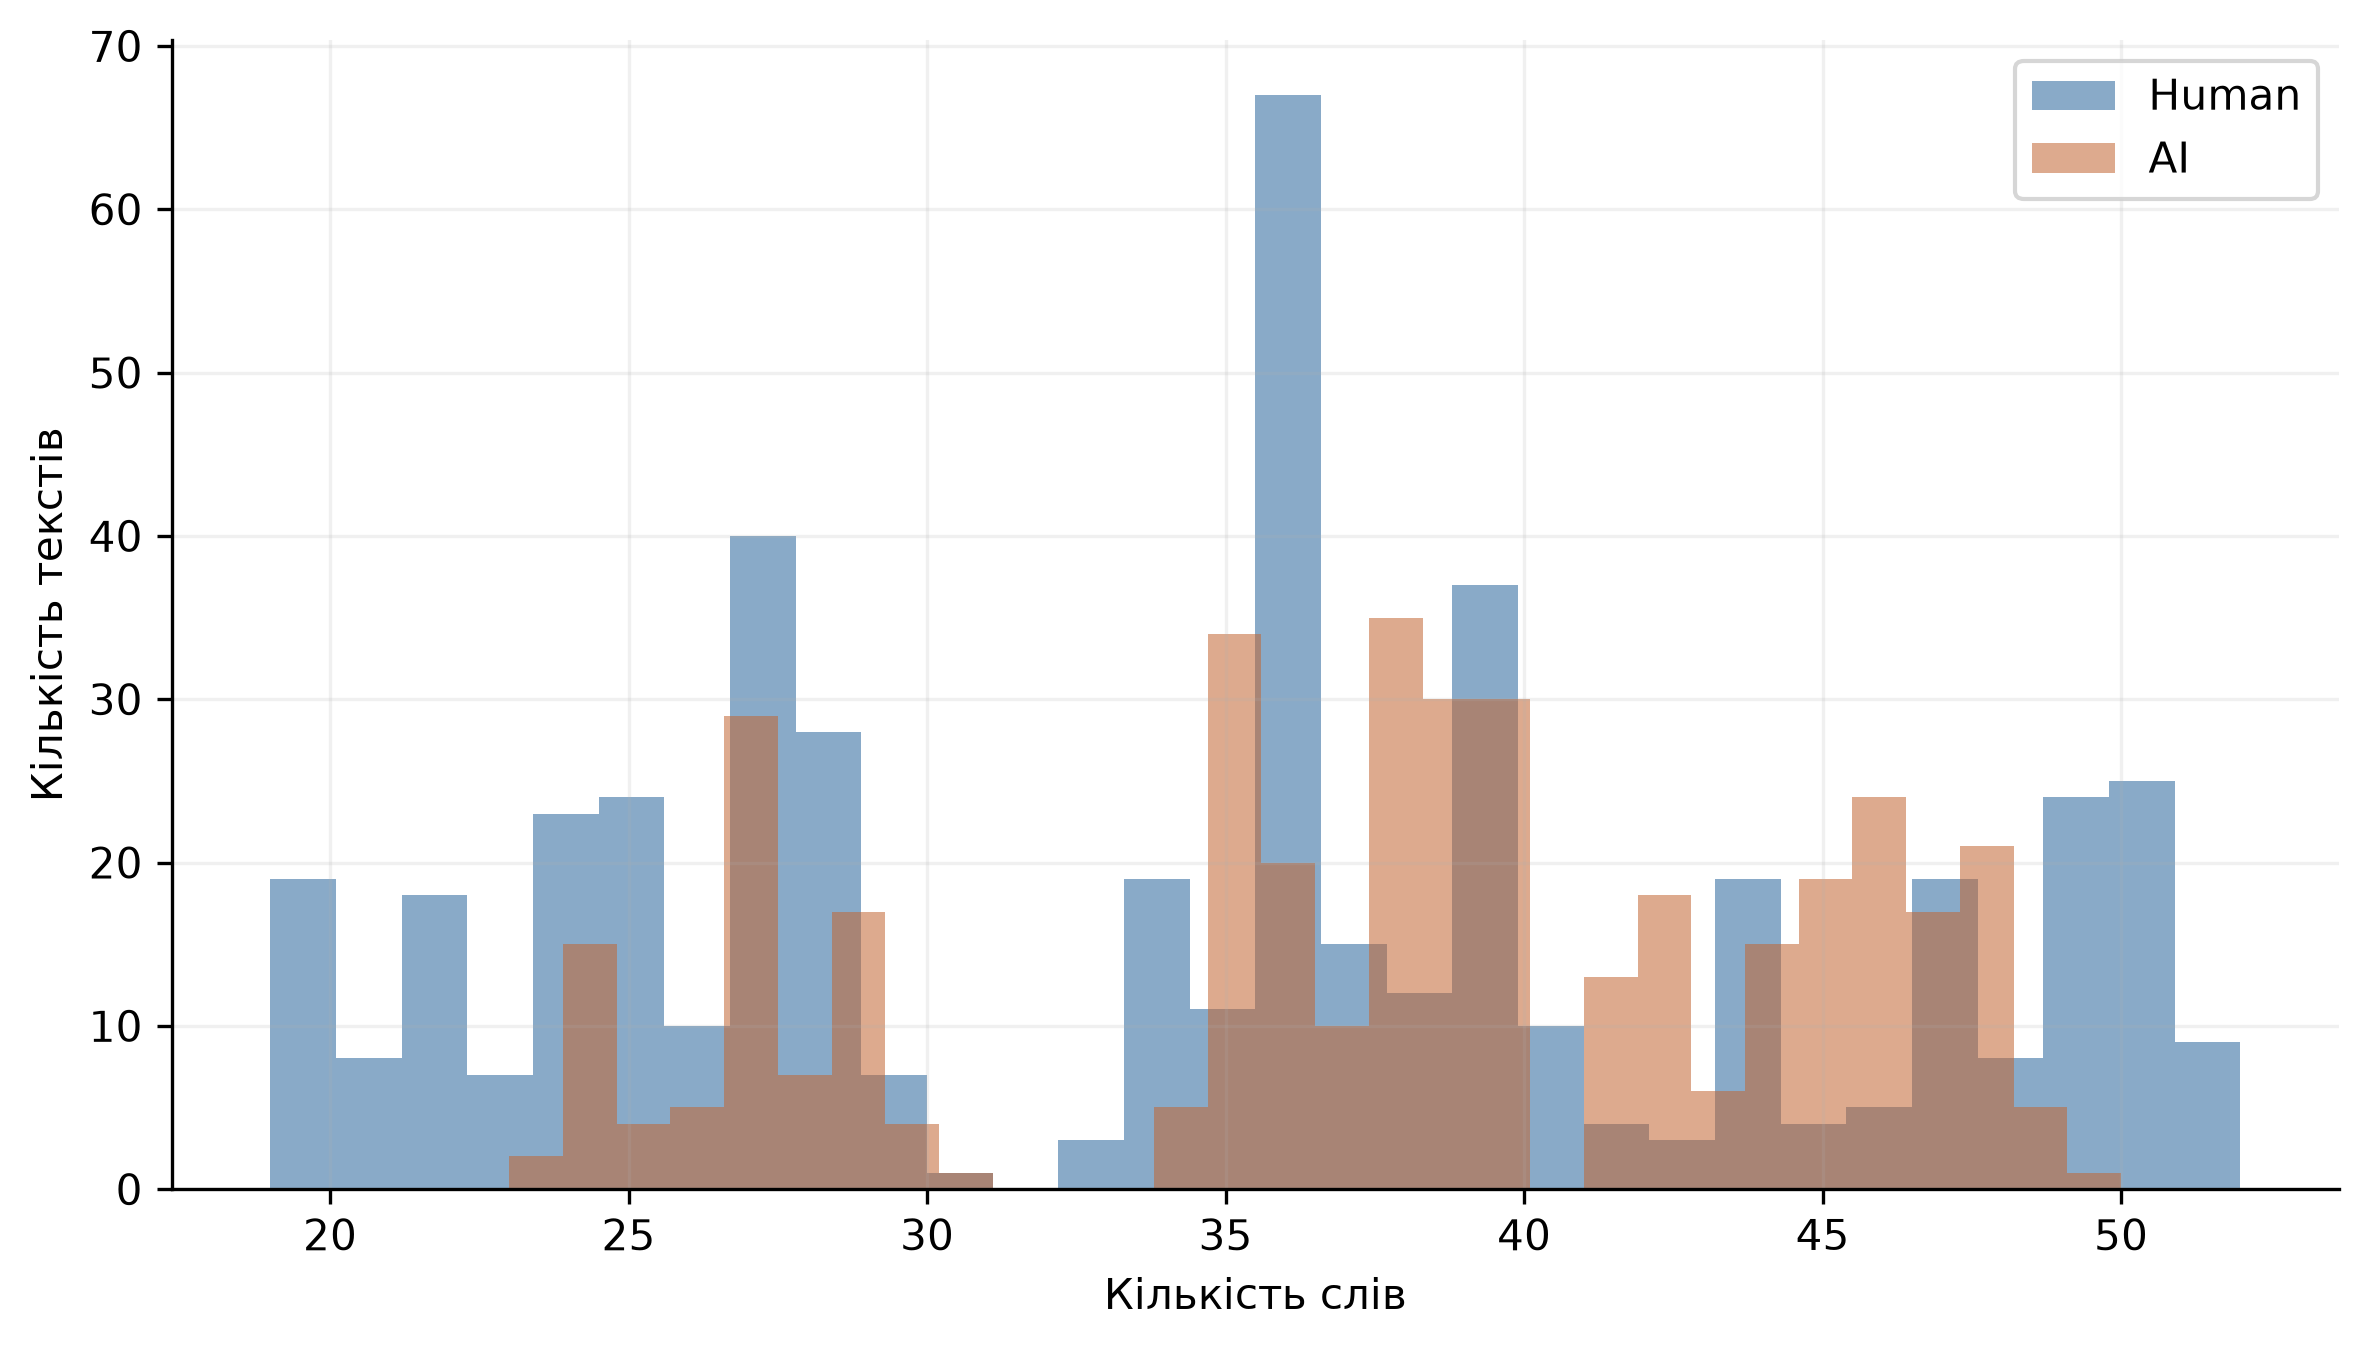

In [14]:
display(Image(filename=str(ROOT / 'lab_03' / 'results' / 'text_lengths.png')))

### Рисунок 2. Macro-F1 та ROC-AUC шести комбінацій

На рисунку 2 зображено macro-F1 та ROC-AUC шести комбінацій. Ідеальні оцінки на одному наборі не свідчать про універсальність детектора. Зважування TF-IDF у цьому поділі не має простору для поліпшення F1.

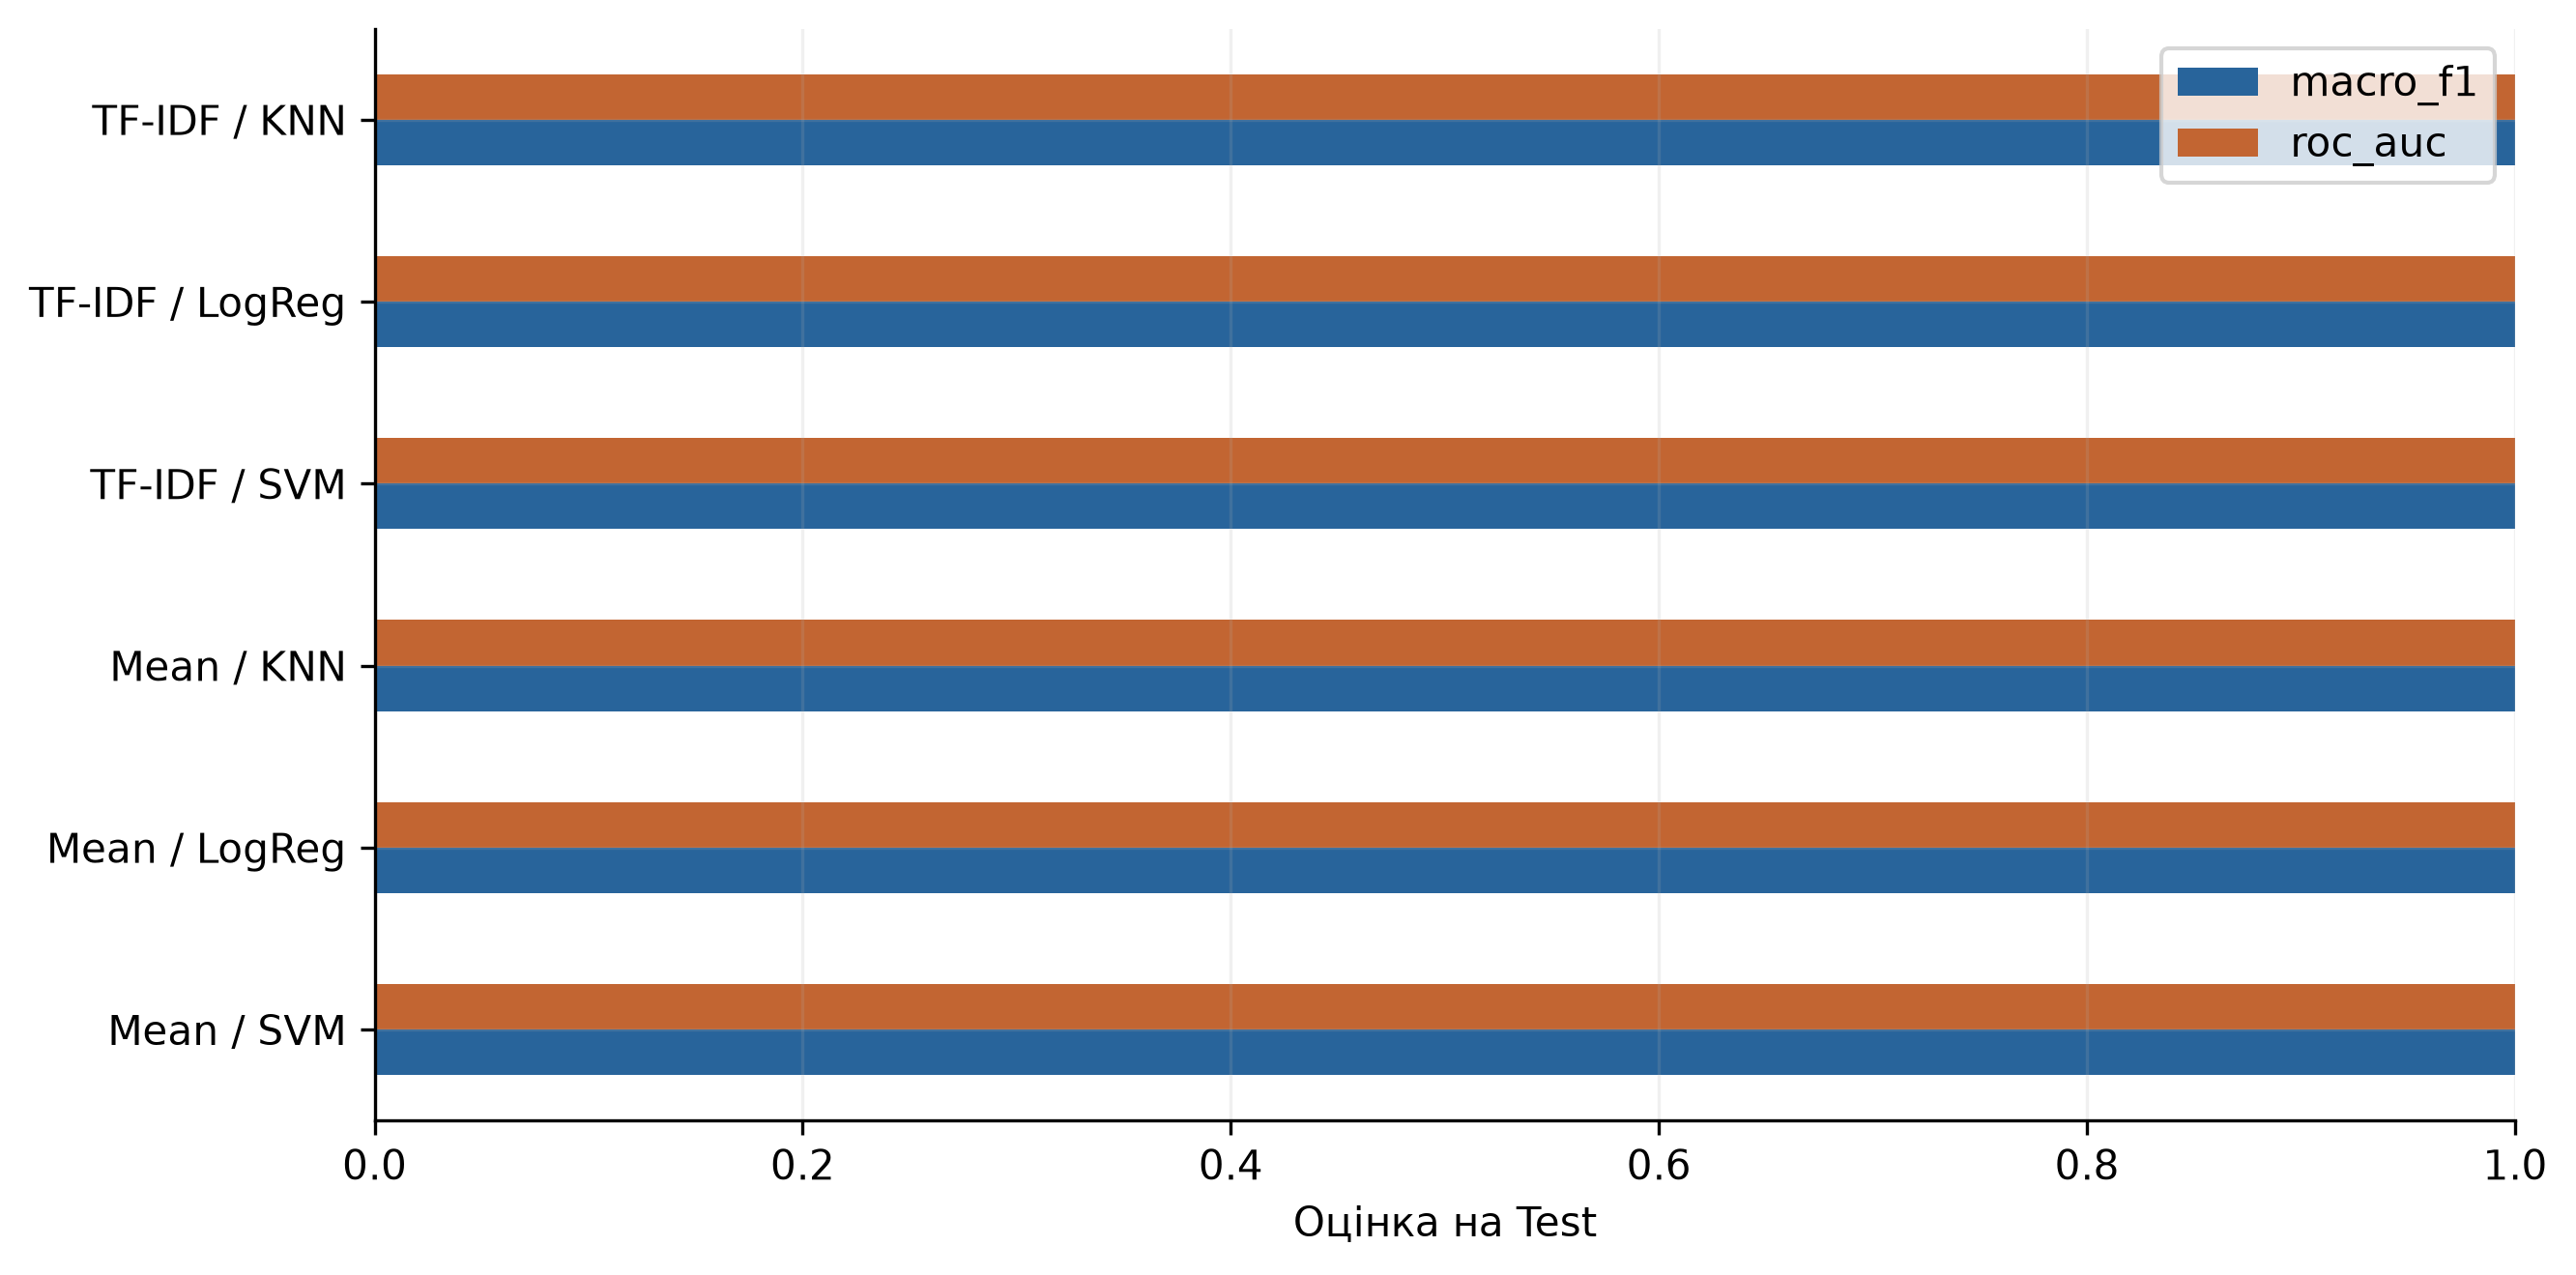

In [15]:
display(Image(filename=str(ROOT / 'lab_03' / 'results' / 'model_comparison.png')))

### Рисунок 3. t-SNE тестових документів для двох агрегацій

На рисунку 3 зображено t-SNE тестових документів для двох агрегацій. Проєкції побудовано для наочності після навчання моделей. Вони не використовувалися як ознаки класифікаторів.

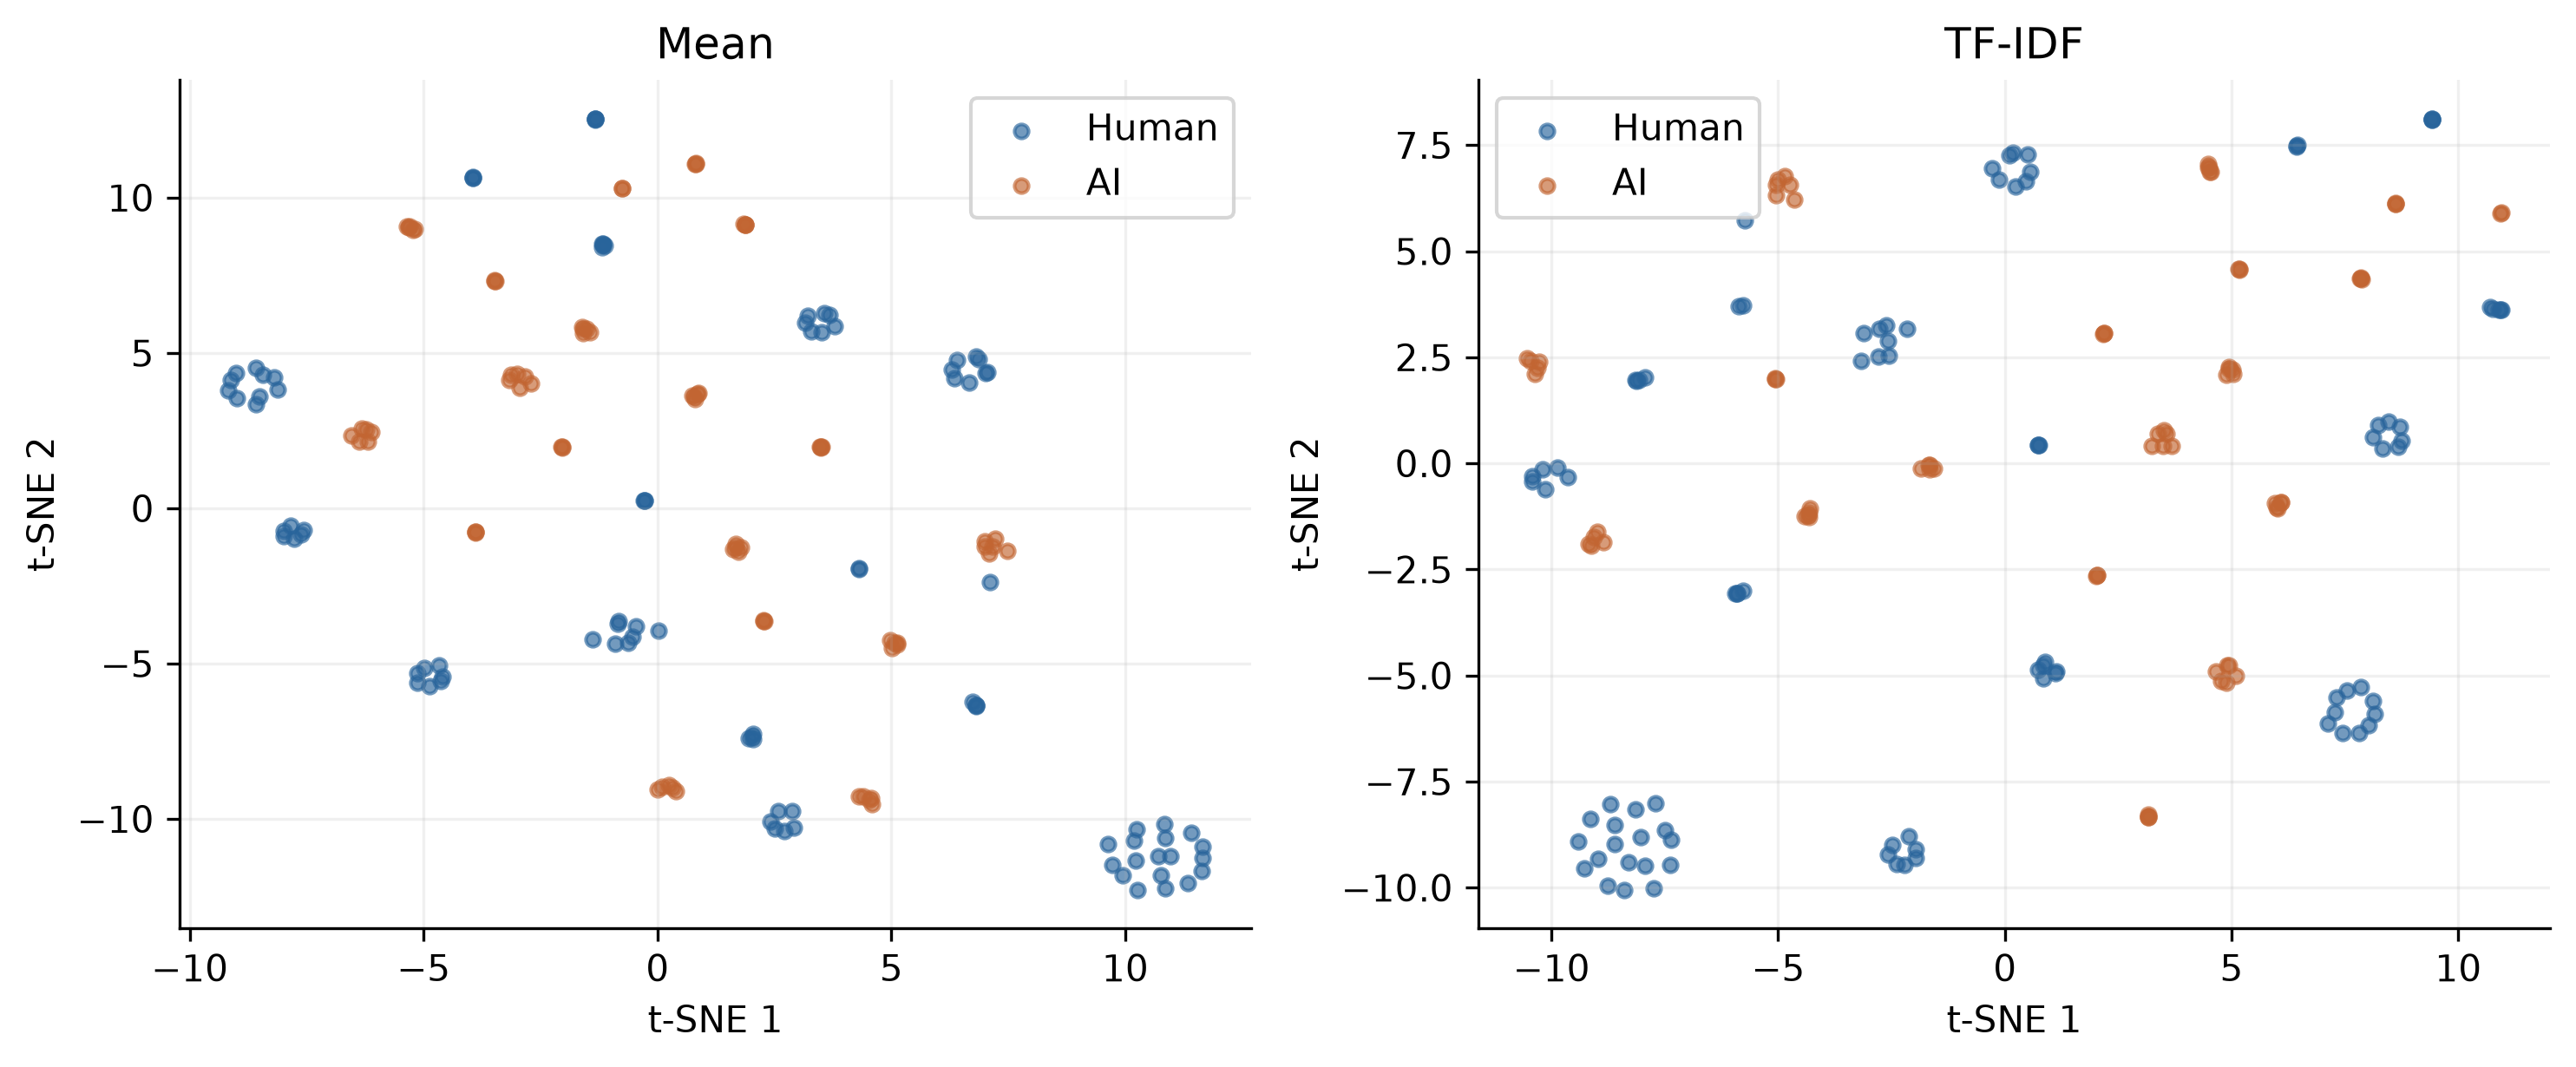

In [16]:
display(Image(filename=str(ROOT / 'lab_03' / 'results' / 'document_spaces.png')))

### Рисунок 4. Слова з високим середнім TF-IDF у Train класу AI

На рисунку 4 зображено слова з високим середнім TF-IDF у Train класу AI. Це характерна лексика саме цього набору. Вона не є універсальним доказом штучного авторства.

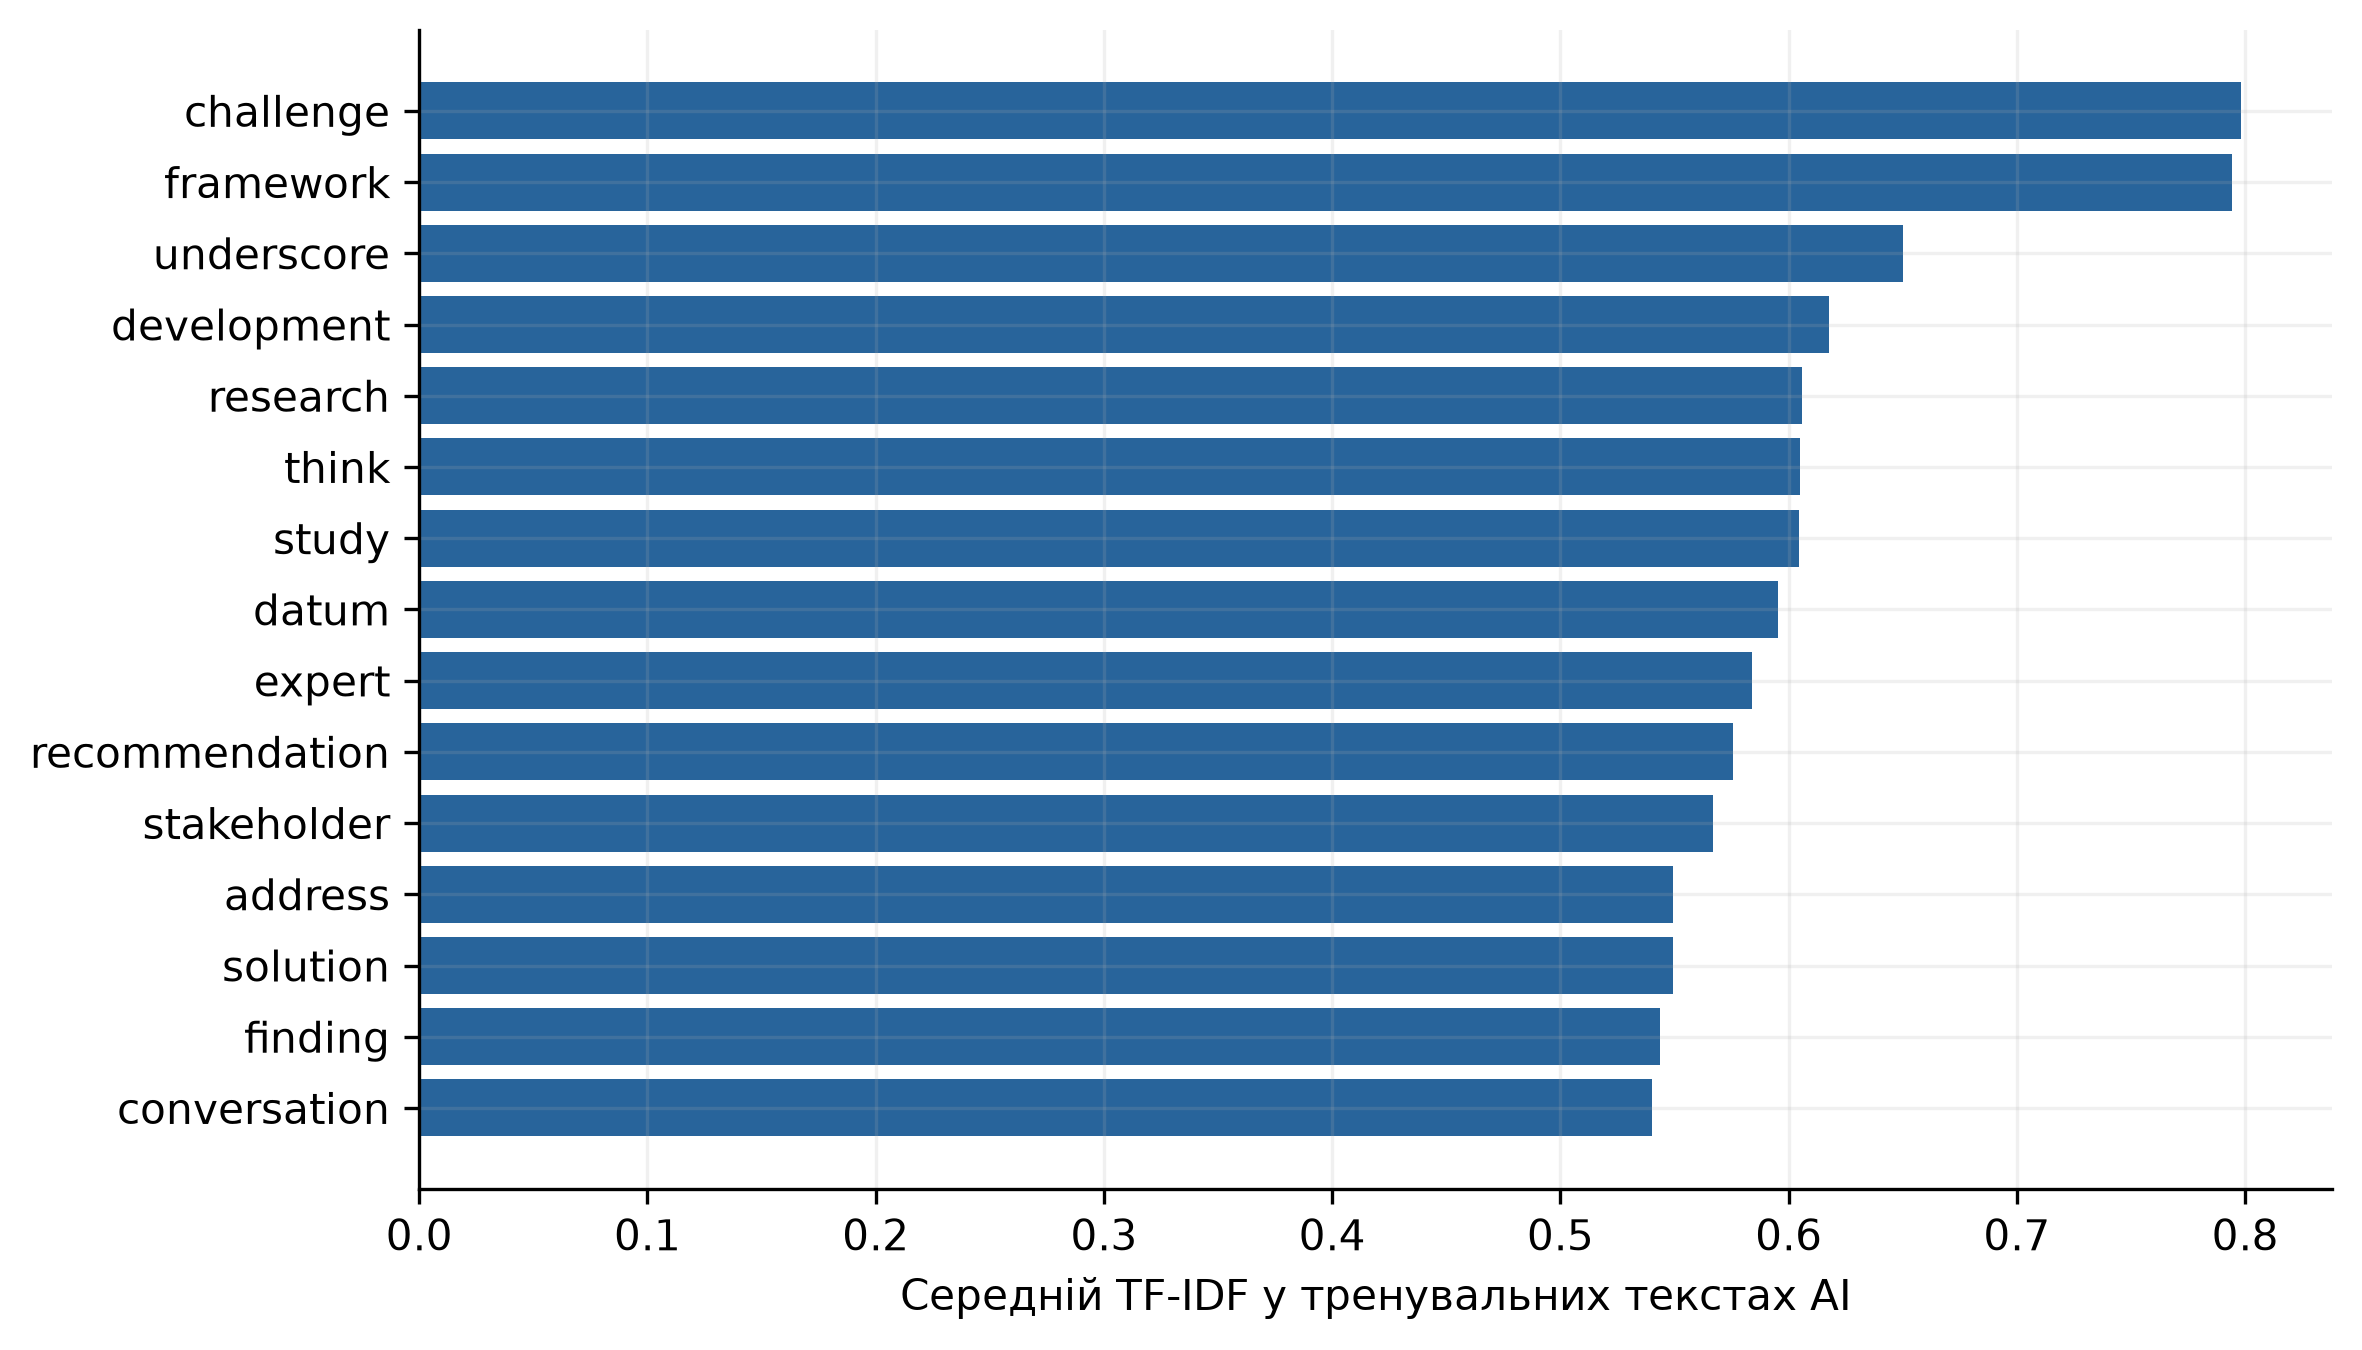

In [17]:
display(Image(filename=str(ROOT / 'lab_03' / 'results' / 'ai_vocabulary.png')))

### Рисунок 5. Матриця плутанини: Mean, SVM

На рисунку 5 зображено матриця плутанини: Mean, SVM. Оцінка отримана на тому самому Test-поділі, що й для інших комбінацій.

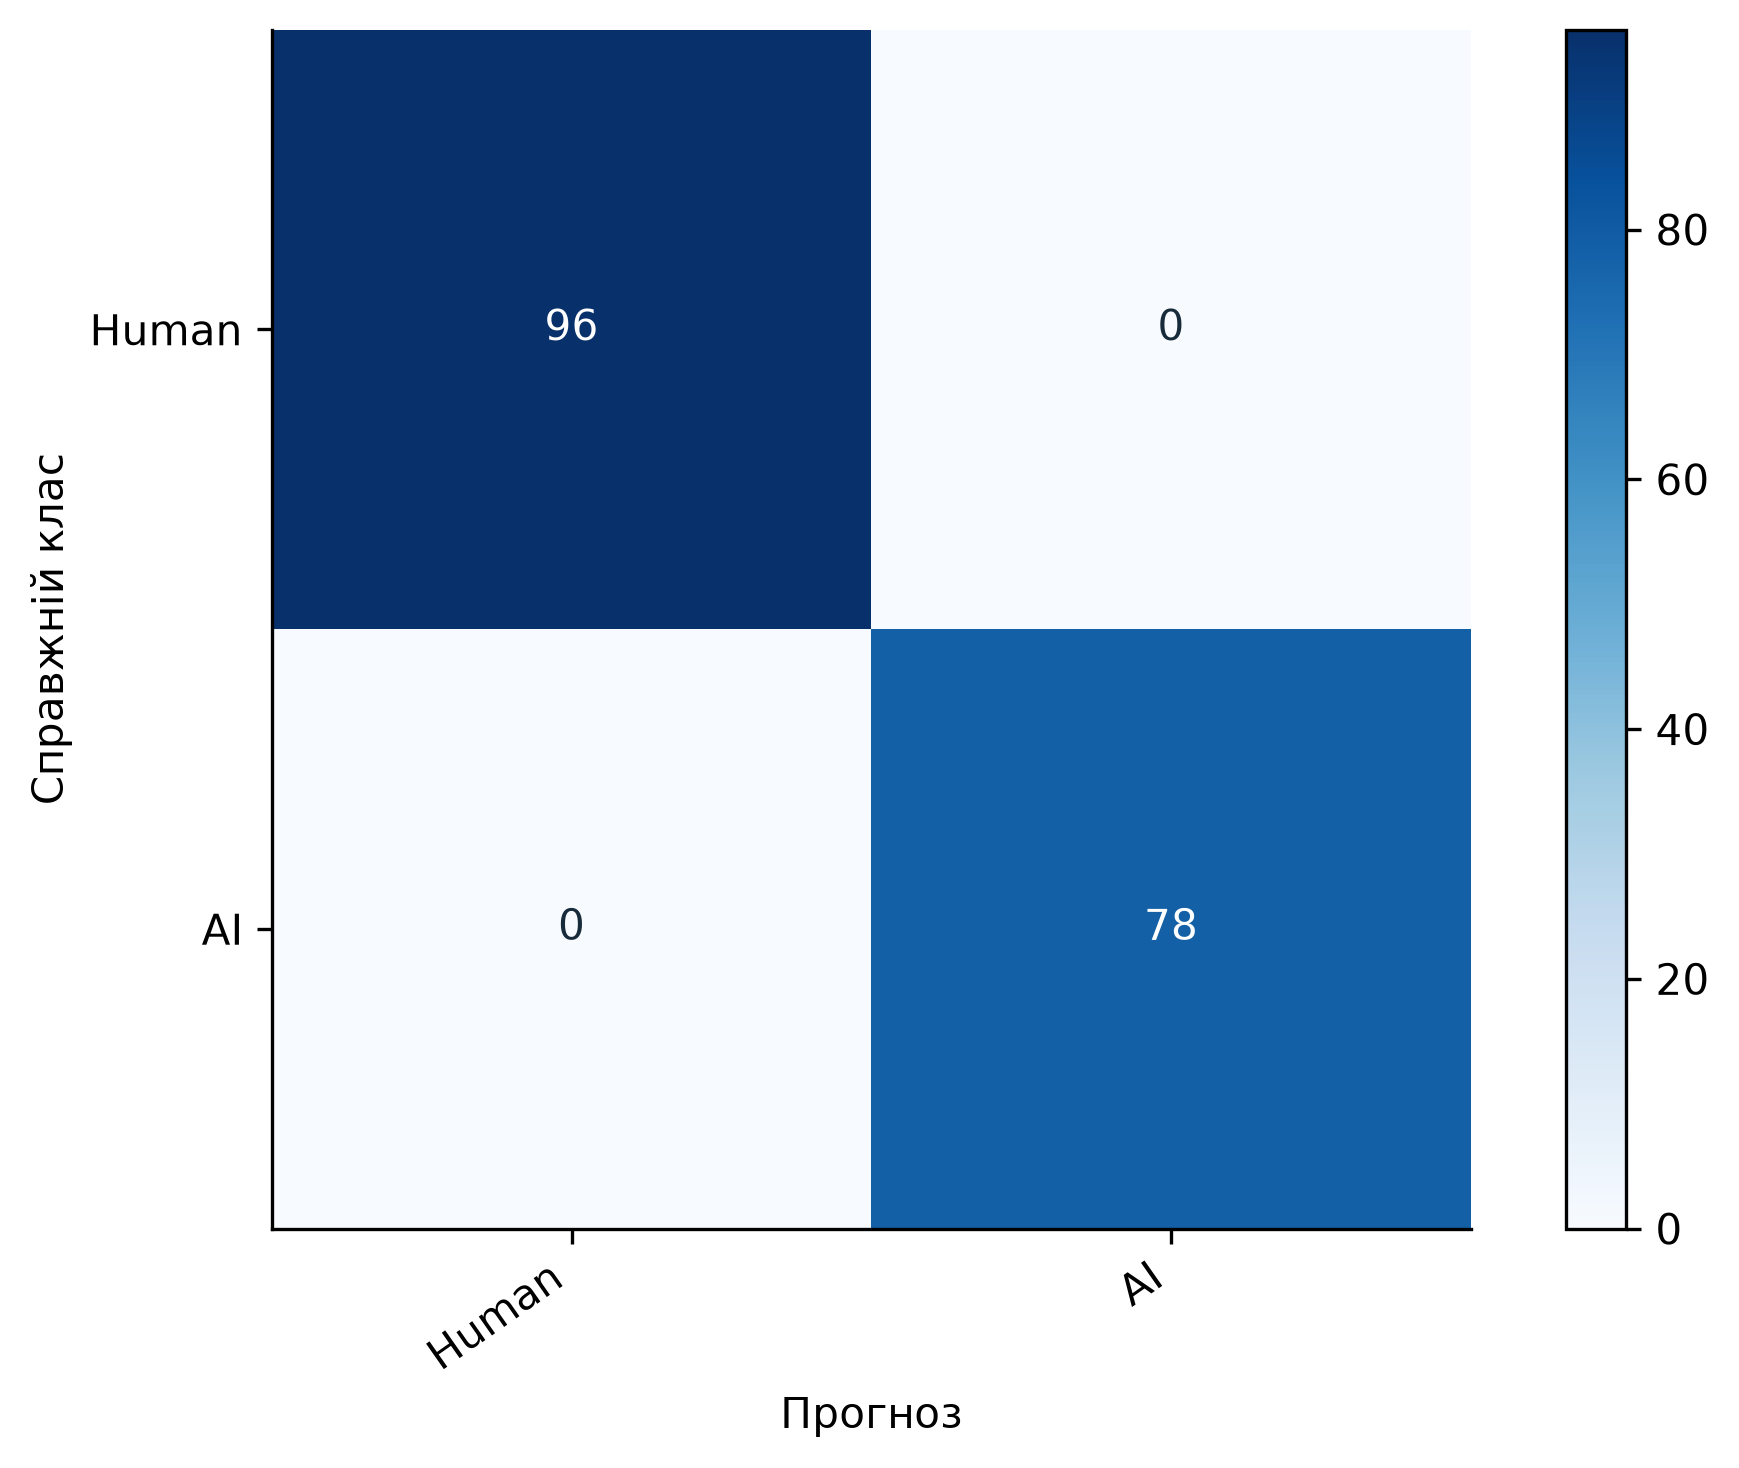

In [18]:
display(Image(filename=str(ROOT / 'lab_03' / 'results' / 'confusion_Mean_SVM.png')))

### Рисунок 6. Матриця плутанини: Mean, LogReg

На рисунку 6 зображено матриця плутанини: Mean, LogReg. Оцінка отримана на тому самому Test-поділі, що й для інших комбінацій.

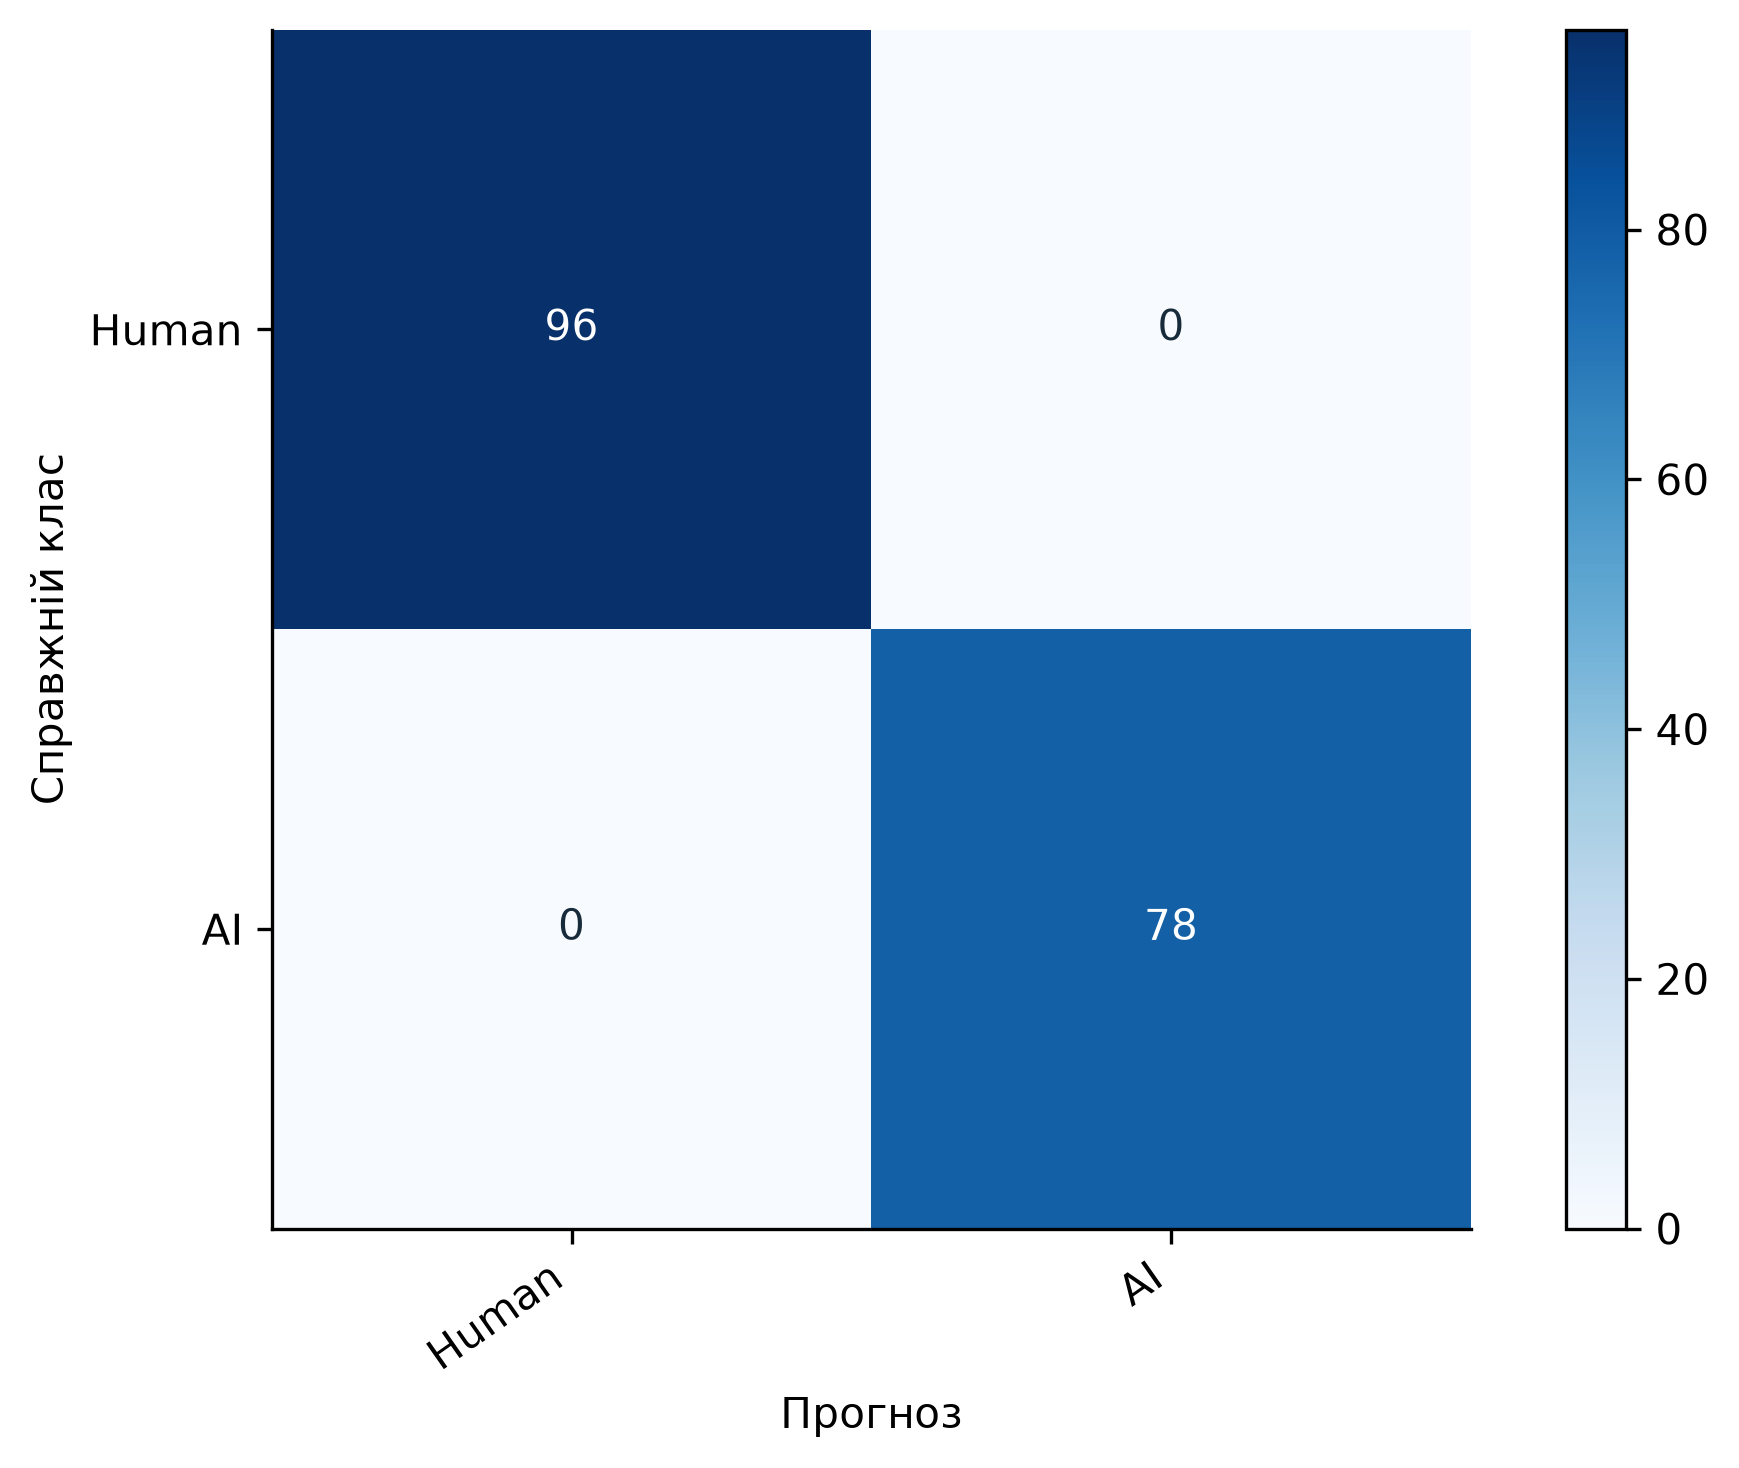

In [19]:
display(Image(filename=str(ROOT / 'lab_03' / 'results' / 'confusion_Mean_LogReg.png')))

### Рисунок 7. Матриця плутанини: Mean, KNN

На рисунку 7 зображено матриця плутанини: Mean, KNN. Оцінка отримана на тому самому Test-поділі, що й для інших комбінацій.

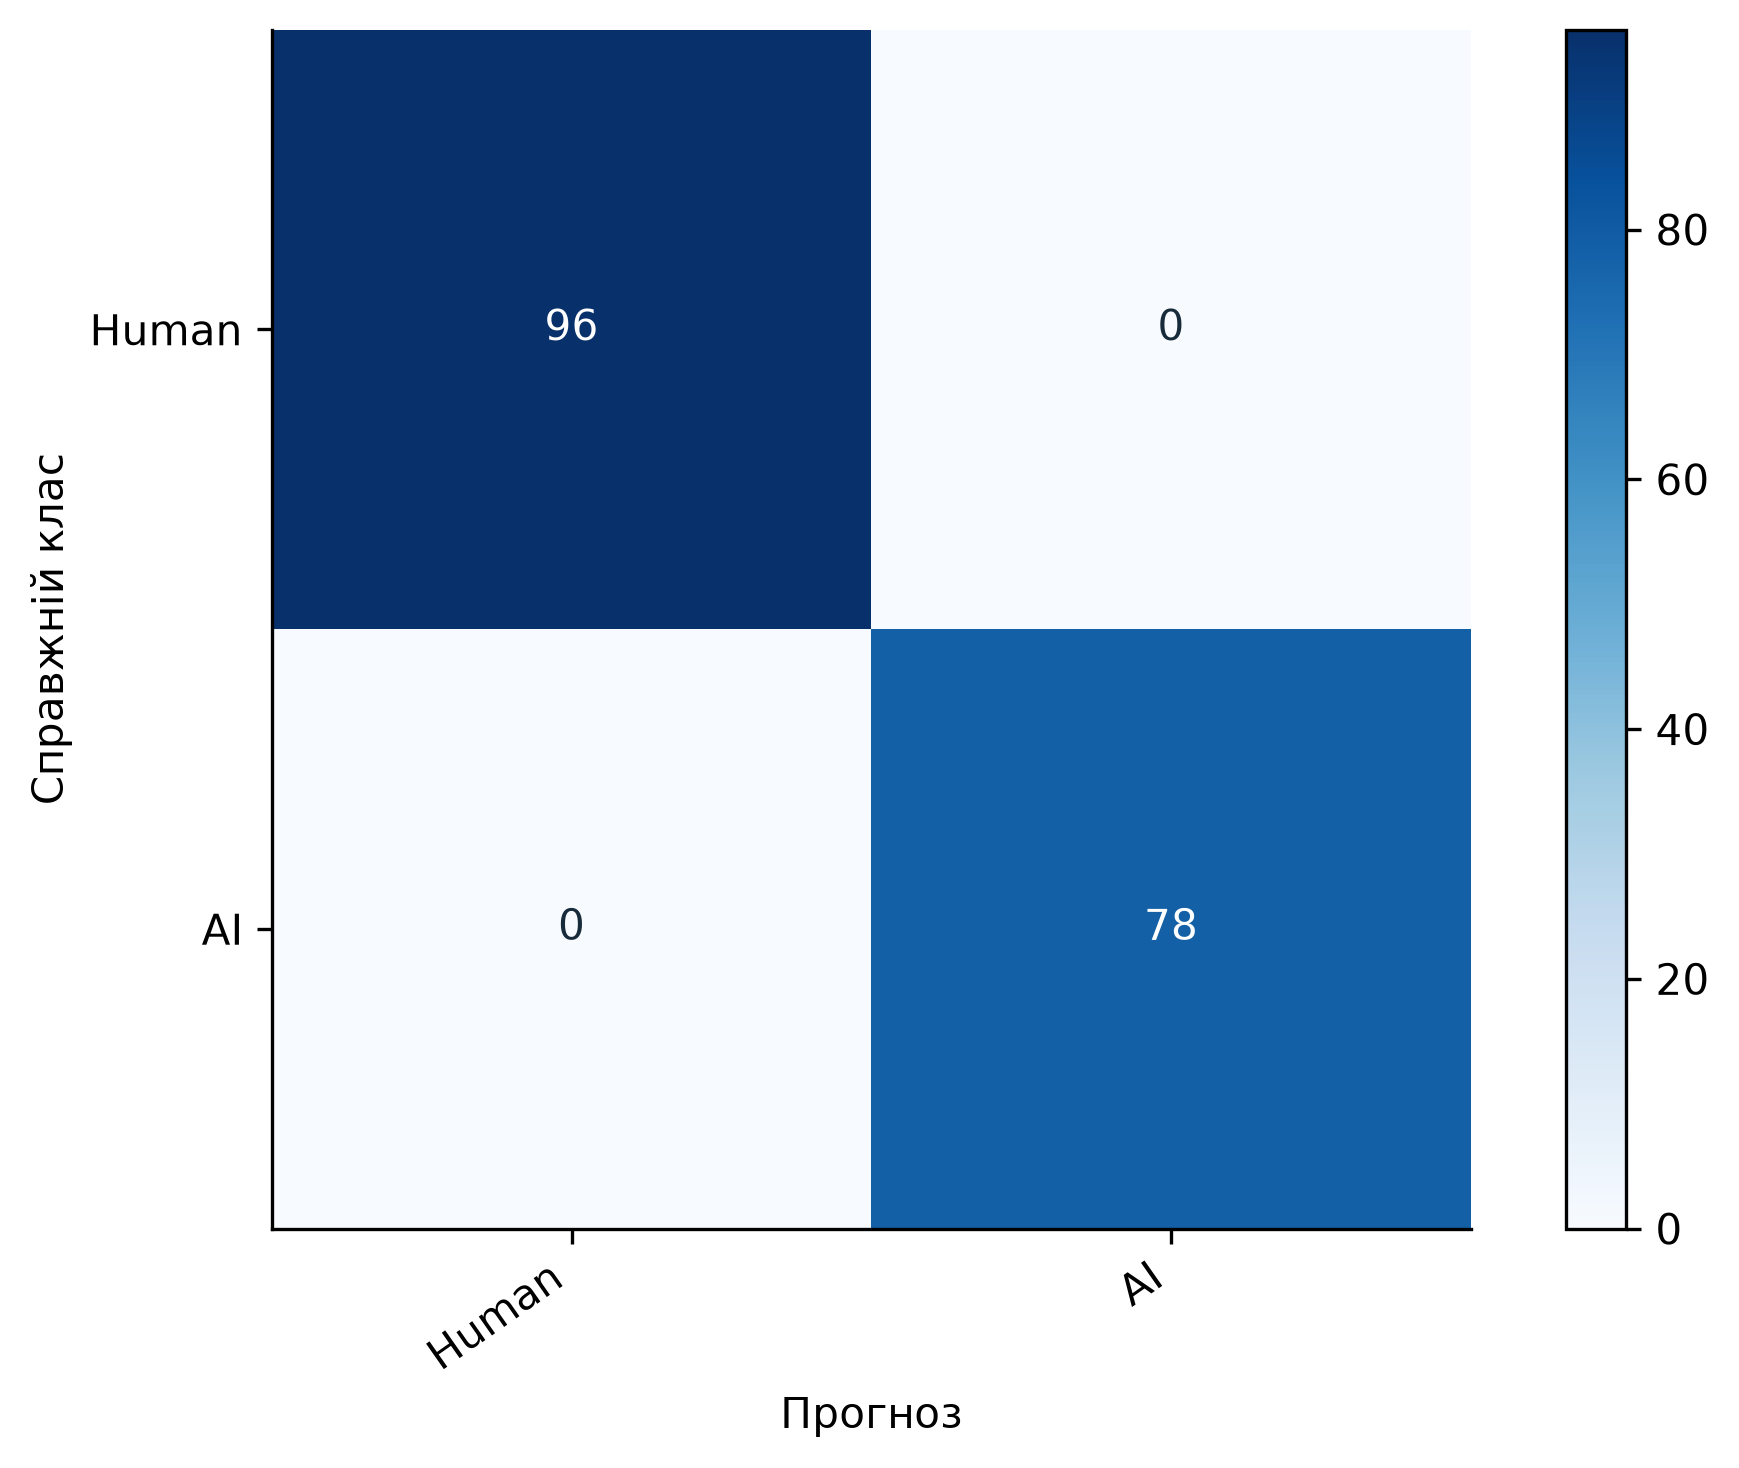

In [20]:
display(Image(filename=str(ROOT / 'lab_03' / 'results' / 'confusion_Mean_KNN.png')))

### Рисунок 8. Матриця плутанини: TFIDF, SVM

На рисунку 8 зображено матриця плутанини: TFIDF, SVM. Оцінка отримана на тому самому Test-поділі, що й для інших комбінацій.

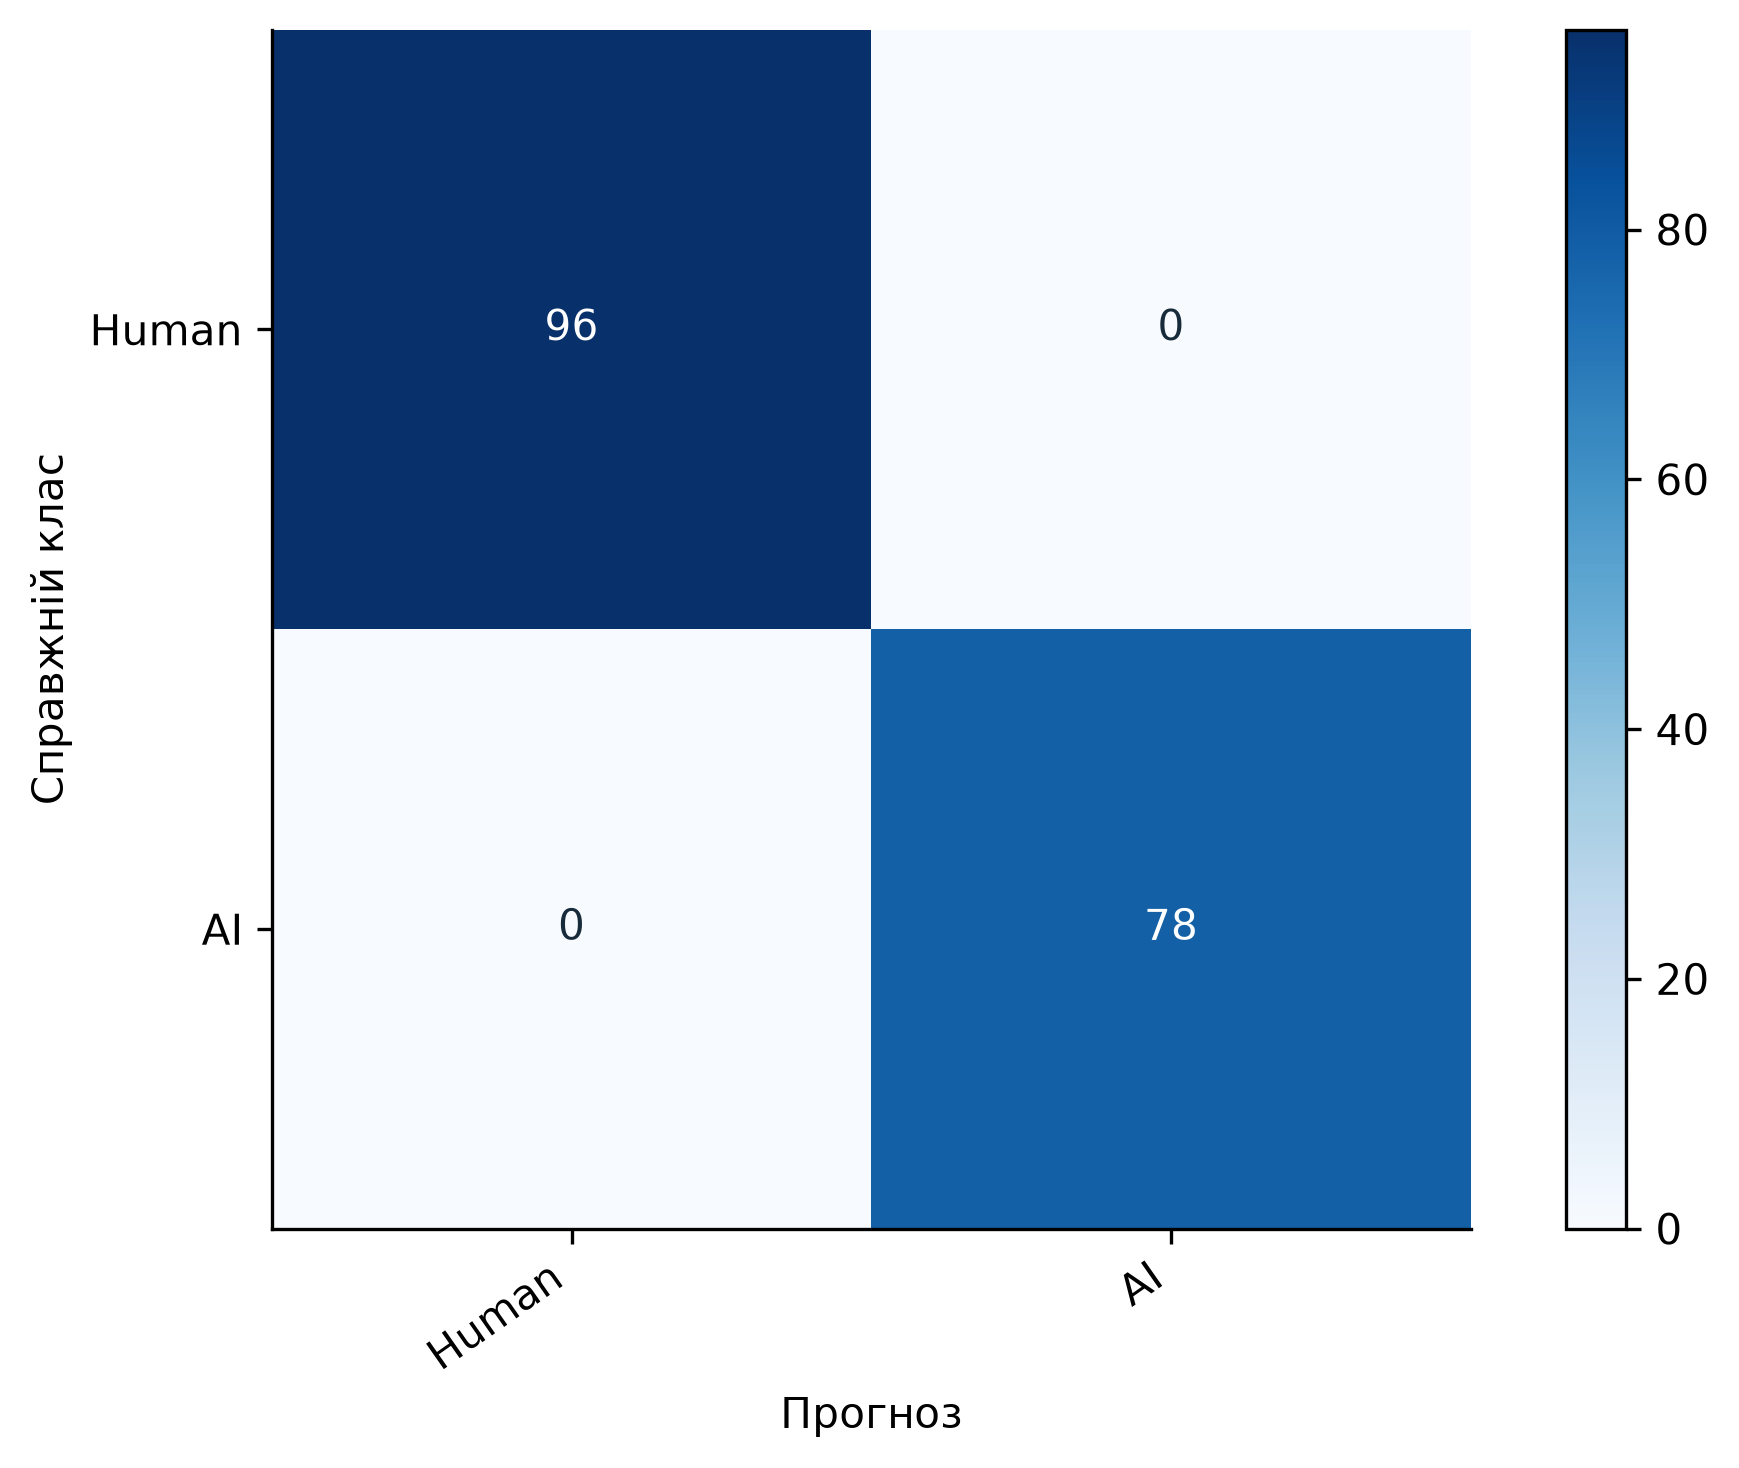

In [21]:
display(Image(filename=str(ROOT / 'lab_03' / 'results' / 'confusion_TFIDF_SVM.png')))

### Рисунок 9. Матриця плутанини: TFIDF, LogReg

На рисунку 9 зображено матриця плутанини: TFIDF, LogReg. Оцінка отримана на тому самому Test-поділі, що й для інших комбінацій.

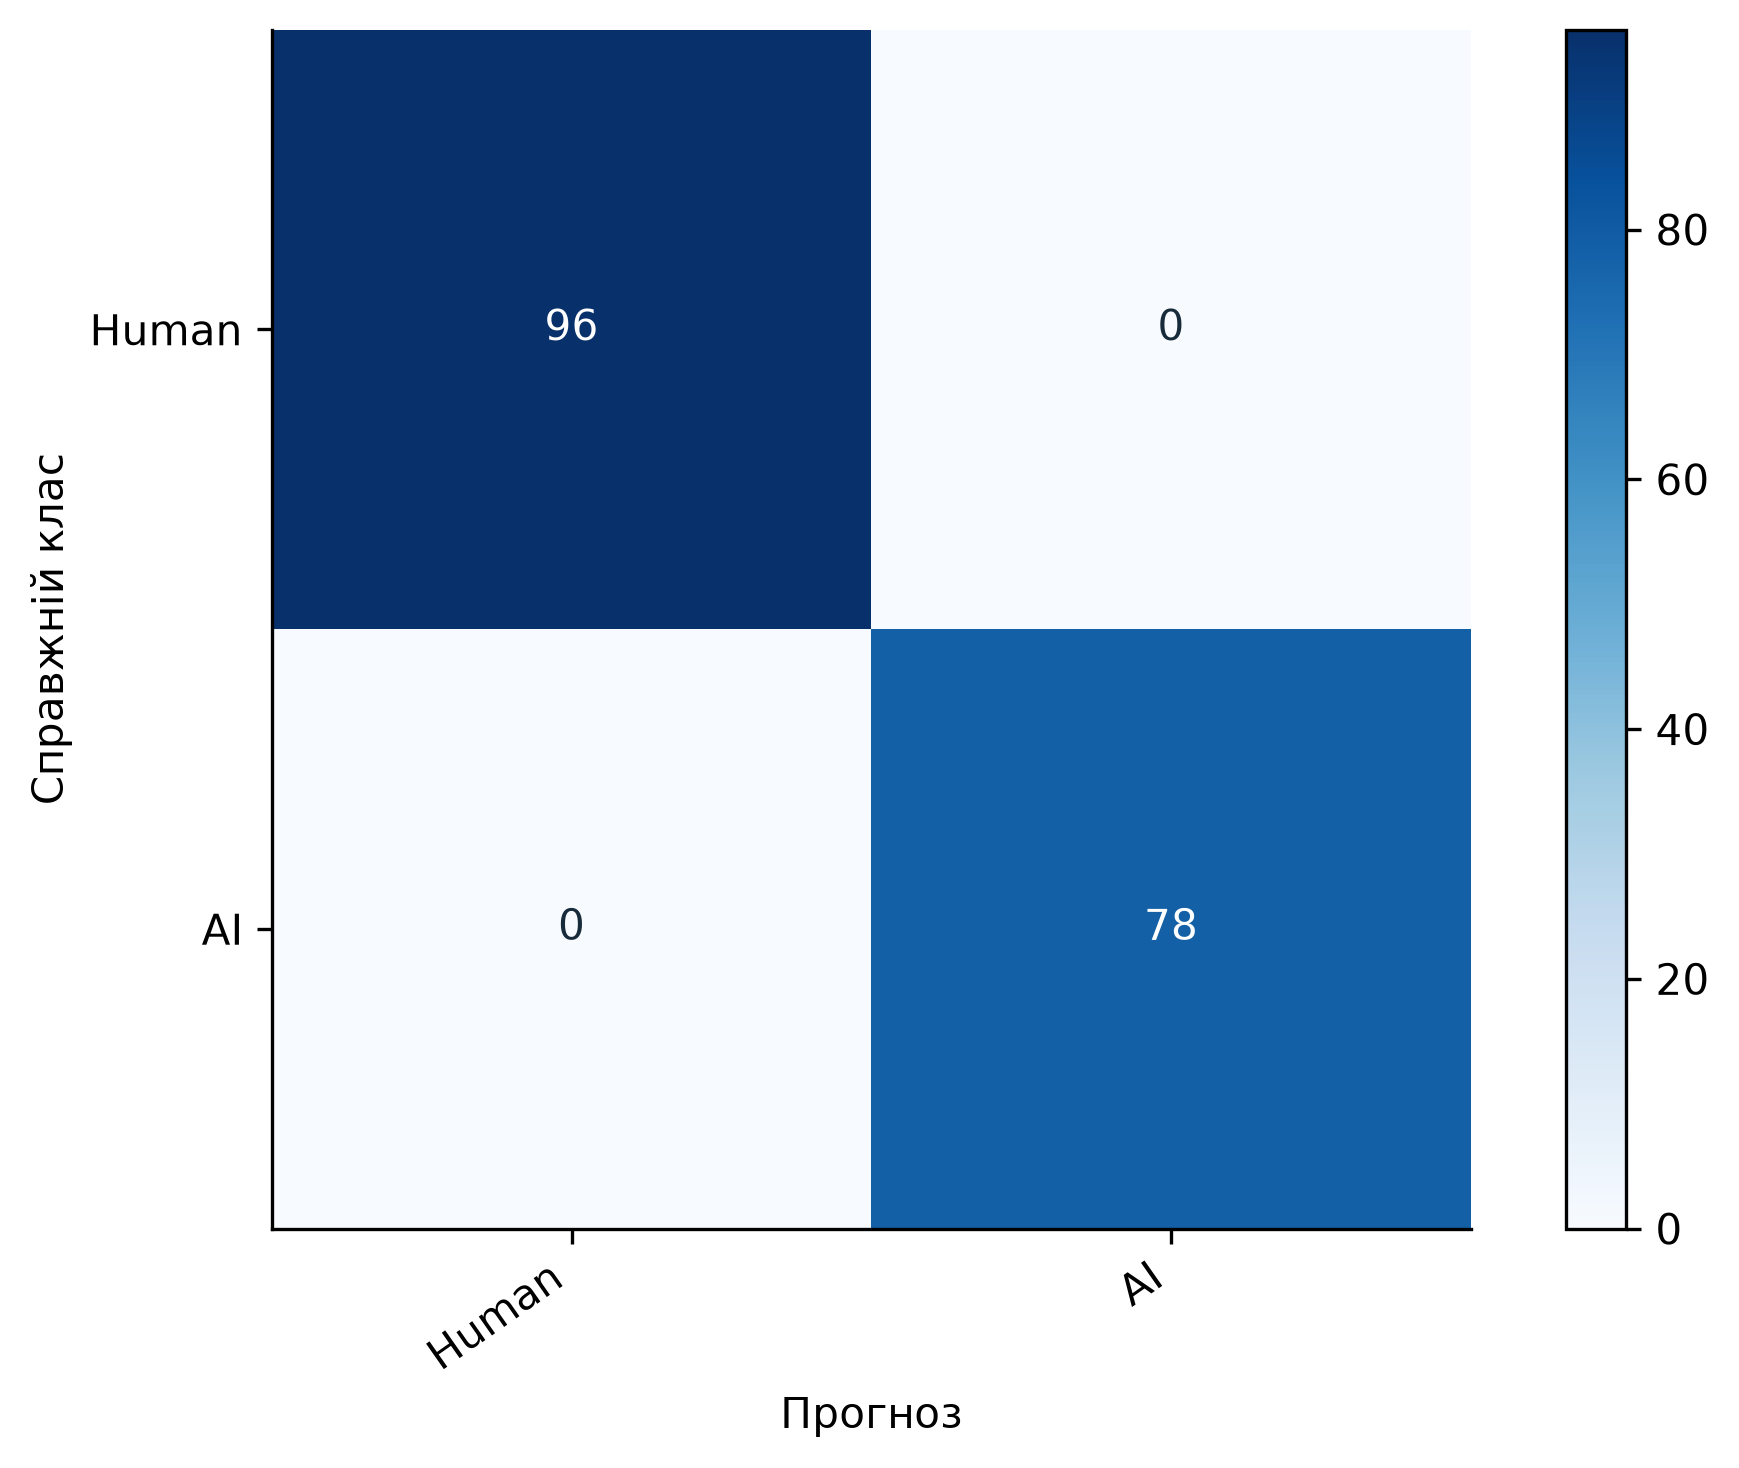

In [22]:
display(Image(filename=str(ROOT / 'lab_03' / 'results' / 'confusion_TFIDF_LogReg.png')))

### Рисунок 10. Матриця плутанини: TFIDF, KNN

На рисунку 10 зображено матриця плутанини: TFIDF, KNN. Оцінка отримана на тому самому Test-поділі, що й для інших комбінацій.

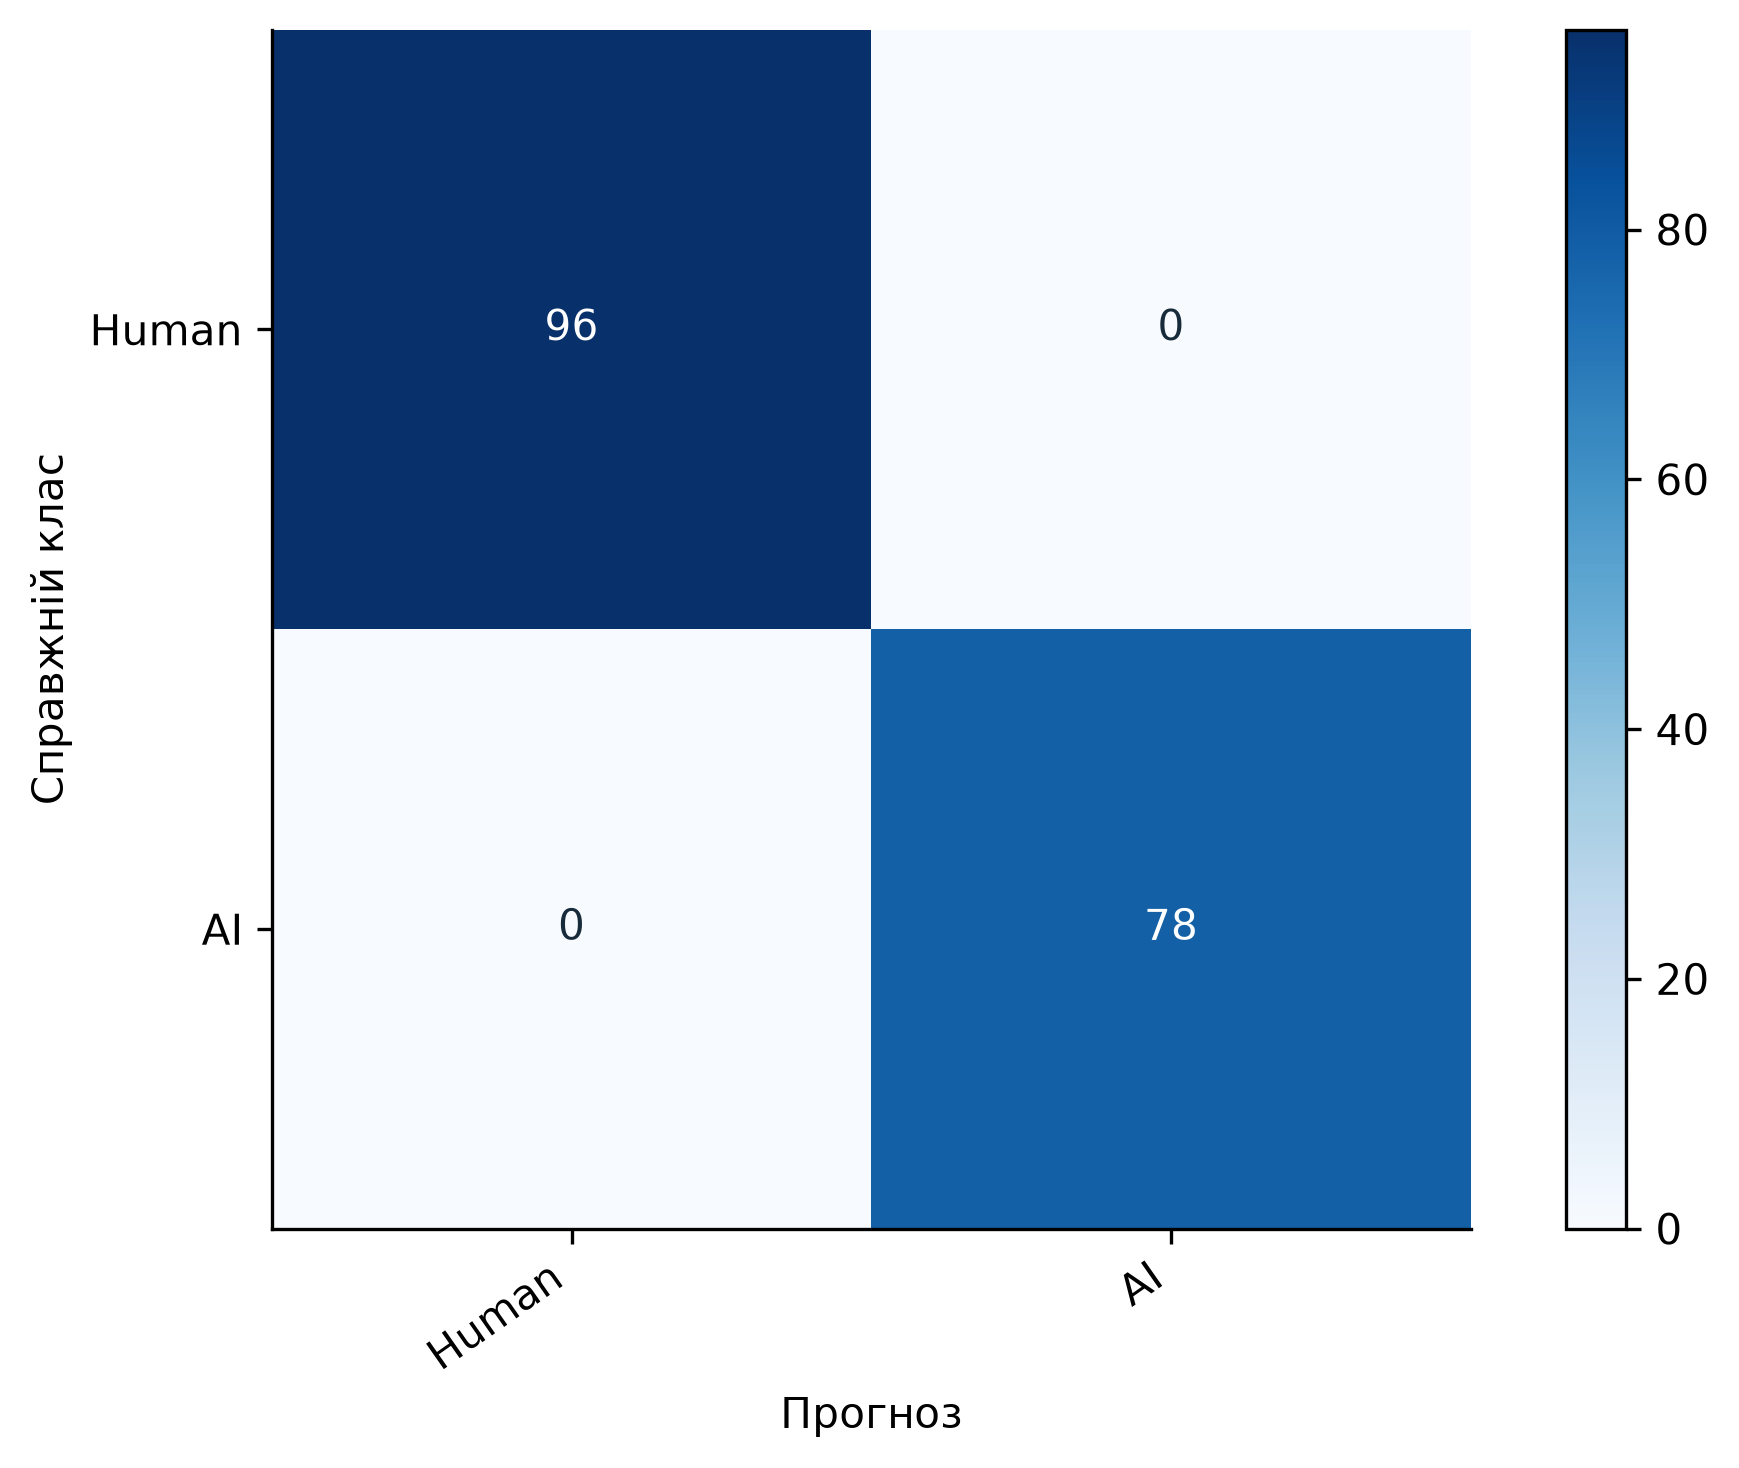

In [23]:
display(Image(filename=str(ROOT / 'lab_03' / 'results' / 'confusion_TFIDF_KNN.png')))

## Висновки

In [24]:
for text in conclusions(3, R):
    print(text)

Після очищення використав 866 текстів. На стратифікованому Test усі шість комбінацій отримали macro-F1=1,0000. Тому цей експеримент не показує переваги TF-IDF за F1 на звичайному поділі.
Додатковий груповий поділ не має спільних тем: 24 у Train і 6 у Test. Виявлено шаблонні способи створення даних, тому високі оцінки не переношу на довільні тексти й не трактую як підтвердження авторства конкретної людини.


## Джерела

Ali Taqi Shah. AI vs Human Text Classification Dataset 2026. Kaggle. https://www.kaggle.com/datasets/alitaqishah/ai-vs-human-text-classification-dataset-2026

Bojanowski P. et al. Enriching Word Vectors with Subword Information. https://arxiv.org/abs/1607.04606